<a href="https://colab.research.google.com/github/elmerzoukiibrahim2537encg-commits/DS_F3_ELMERZOUKI_IBRAHIM_ELHACHAM_RACHID_FIN2/blob/main/Projet_F3_Previsions_Inflation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TP F3 : Prévision de l'inflation à 12 mois

**Thème :** séries temporelles et apprentissage automatique · **Niveau :** premier cycle universitaire



## 1. De quel type d'apprentissage s'agit-il ?

La question étudiée est : **le taux de chômage et le taux directeur aident-ils à prévoir l'inflation annuelle américaine 12 mois à l'avance ?**

Il s'agit d'un problème d'**apprentissage supervisé**, plus précisément d'une **régression** :

- **Supervisé** : chaque ligne d'entraînement contient des variables explicatives et une valeur d'inflation cible connue.
- **Régression** : la cible est numérique et continue (un taux d'inflation en pourcentage).
- **Séries temporelles** : les observations sont ordonnées par mois. Il est donc interdit de mélanger aléatoirement les dates lors du découpage entraînement/test.

À la date d'origine `t`, le modèle utilise les informations disponibles jusqu'à `t` pour prévoir l'inflation annuelle observée en `t+12`.

## 2. Les données

Les trois séries proviennent de **FRED (Federal Reserve Economic Data)**.

| Variable | Code FRED | Description |
|---|---|---|
| `CPIAUCSL` | CPIAUCSL | Indice des prix à la consommation, corrigé des variations saisonnières |
| `UNRATE` | UNRATE | Taux de chômage américain, en % |
| `FEDFUNDS` | FEDFUNDS | Taux effectif des fonds fédéraux, en % |

Les fichiers CSV fournis sont chargés depuis le même dossier que ce notebook. Les URLs FRED sont utilisées en solution de secours si les fichiers locaux ne sont pas présents.

In [14]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.inspection import permutation_importance

np.random.seed(42)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

DOSSIER = Path(".")
URLS = {
    "CPIAUCSL": "https://fred.stlouisfed.org/graph/fredgraph.csv?id=CPIAUCSL",
    "UNRATE": "https://fred.stlouisfed.org/graph/fredgraph.csv?id=UNRATE",
    "FEDFUNDS": "https://fred.stlouisfed.org/graph/fredgraph.csv?id=FEDFUNDS",
}

def charger_serie(code):
    fichier = DOSSIER / f"{code}.csv"
    if fichier.exists():
        data = pd.read_csv(fichier)
    else:
        data = pd.read_csv(URLS[code])
    data.columns = ["date", code]
    data["date"] = pd.to_datetime(data["date"])
    data[code] = pd.to_numeric(data[code], errors="coerce")
    return data

cpi = charger_serie("CPIAUCSL")
chomage = charger_serie("UNRATE")
taux = charger_serie("FEDFUNDS")

print("CPI :", cpi.shape, "| Chômage :", chomage.shape, "| Taux directeur :", taux.shape)

CPI : (957, 2) | Chômage : (945, 2) | Taux directeur : (868, 2)


## 3. Première exploration

On examine les dates couvertes, les types de variables, les valeurs manquantes et les statistiques descriptives. Les séries ne commencent pas toutes à la même date : la fusion sur la date commune permettra de travailler sur une période cohérente.

In [15]:
for nom, serie in [("CPI", cpi), ("UNRATE", chomage), ("FEDFUNDS", taux)]:
    print(f"\n{nom}")
    print("Période :", serie["date"].min().date(), "à", serie["date"].max().date())
    print("Valeurs manquantes :", serie.isna().sum().to_dict())
    display(serie.describe().round(2))


CPI
Période : 1947-01-01 à 2026-09-01
Valeurs manquantes : {'date': 0, 'CPIAUCSL': 1}


,date,CPIAUCSL
count,957,956.00
mean,1986-10-31 13:14:28.965517248,125.81
min,1947-01-01 00:00:00,21.48
25%,1966-12-01 00:00:00,32.89
50%,1986-11-01 00:00:00,110.30
75%,2006-10-01 00:00:00,202.82
max,2026-09-01 00:00:00,336.30
std,NaN,91.04



UNRATE
Période : 1948-01-01 à 2026-09-01
Valeurs manquantes : {'date': 0, 'UNRATE': 1}


,date,UNRATE
count,945,944.00
mean,1987-05-02 04:20:34.285714304,5.65
min,1948-01-01 00:00:00,2.50
25%,1967-09-01 00:00:00,4.30
50%,1987-05-01 00:00:00,5.45
75%,2007-01-01 00:00:00,6.70
max,2026-09-01 00:00:00,14.80
std,NaN,1.70



FEDFUNDS
Période : 1954-07-01 à 2026-10-01
Valeurs manquantes : {'date': 0, 'FEDFUNDS': 0}


,date,FEDFUNDS
count,868,868.00
mean,1990-08-16 10:58:37.050691200,4.59
min,1954-07-01 00:00:00,0.05
25%,1972-07-24 06:00:00,1.94
50%,1990-08-16 12:00:00,4.24
75%,2008-09-08 12:00:00,6.10
max,2026-10-01 00:00:00,19.10
std,NaN,3.52


In [16]:
# Fusion des trois séries sur la date d'observation
df = cpi.merge(chomage, on="date", how="inner").merge(taux, on="date", how="inner")
df = df.sort_values("date").dropna().reset_index(drop=True)

print("Dimensions après fusion :", df.shape)
print("Période commune :", df["date"].min().date(), "à", df["date"].max().date())
display(df.head())
display(df.tail())

Dimensions après fusion : (866, 4)
Période commune : 1954-07-01 à 2026-09-01


,date,CPIAUCSL,UNRATE,FEDFUNDS
0,1954-07-01,26.86,5.8,0.80
1,1954-08-01,26.85,6.0,1.22
2,1954-09-01,26.81,6.1,1.07
3,1954-10-01,26.72,5.7,0.85
4,1954-11-01,26.78,5.3,0.83


,date,CPIAUCSL,UNRATE,FEDFUNDS
861,2026-05-01,333.979,4.3,3.63
862,2026-06-01,332.568,4.2,3.63
863,2026-07-01,332.813,4.1,3.63
864,2026-08-01,334.131,4.1,3.63
865,2026-09-01,336.298,4.2,3.75


**Lecture.** La fusion conserve uniquement les mois présents dans les trois fichiers. Le nombre final d'observations est donc inférieur au nombre de lignes du fichier CPI, car les séries `UNRATE` et surtout `FEDFUNDS` commencent plus tard.

## 4. Visualisation des séries économiques

Les graphiques permettent de repérer les tendances, les cycles et les périodes de rupture. Les variables sont exprimées dans des unités différentes ; on les représente séparément.

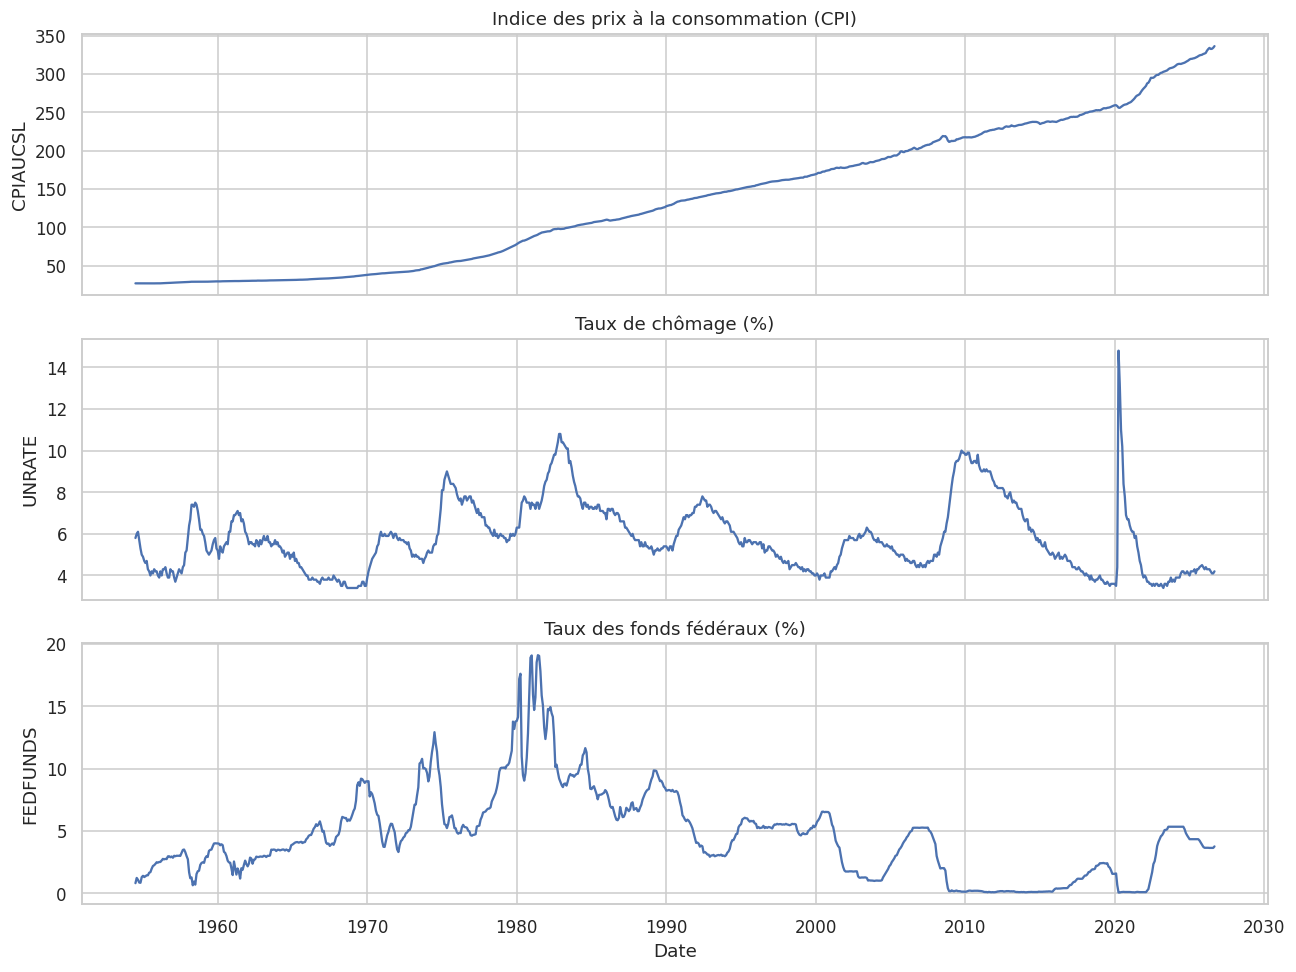

In [17]:
fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
for ax, var, titre in zip(
    axes,
    ["CPIAUCSL", "UNRATE", "FEDFUNDS"],
    ["Indice des prix à la consommation (CPI)", "Taux de chômage (%)", "Taux des fonds fédéraux (%)"]
):
    ax.plot(df["date"], df[var])
    ax.set_title(titre)
    ax.set_ylabel(var)
axes[-1].set_xlabel("Date")
plt.tight_layout()
plt.show()

### 4.1 Construire l'inflation annuelle

L'indice CPI est un niveau de prix, pas directement un taux d'inflation. On calcule donc sa variation sur 12 mois :

\[
Inflation_t = \left(\frac{CPI_t}{CPI_{t-12}} - 1\right)\times 100
\]

Cette mesure correspond à l'inflation annuelle en pourcentage.

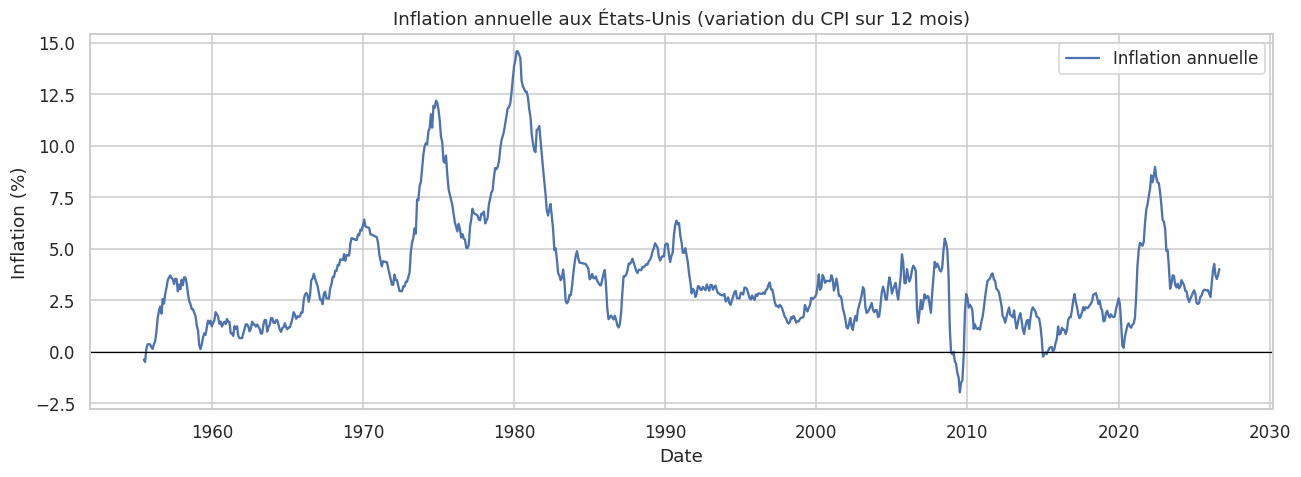

,date,CPIAUCSL,INFLATION
851,2025-06-01,321.44,2.68
852,2025-07-01,322.17,2.74
853,2025-08-01,323.29,2.94
854,2025-09-01,324.24,3.02
855,2025-11-01,325.06,2.99
856,2025-12-01,326.03,3.00
857,2026-01-01,326.59,2.83
858,2026-02-01,327.46,2.66
859,2026-03-01,330.29,3.32
860,2026-04-01,332.41,3.95


In [18]:
df["INFLATION"] = df["CPIAUCSL"].pct_change(12) * 100

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(df["date"], df["INFLATION"], label="Inflation annuelle")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("Inflation annuelle aux États-Unis (variation du CPI sur 12 mois)")
ax.set_ylabel("Inflation (%)")
ax.set_xlabel("Date")
ax.legend()
plt.tight_layout()
plt.show()

display(df[["date", "CPIAUCSL", "INFLATION"]].tail(15).round(2))

**Lecture.** L'inflation annuelle peut augmenter ou diminuer même si le niveau du CPI continue de progresser : elle mesure la vitesse de hausse des prix, et non leur niveau absolu.

## 5. Préparation des données et création des retards

### 5.1 Définir correctement l'horizon de prévision

La date `t` est la date à laquelle on formule la prévision. La cible est l'inflation annuelle 12 mois plus tard :

\[
y_t = Inflation_{t+12}
\]

En Python, cela correspond à `INFLATION.shift(-12)`. Les variables explicatives sont construites à partir des informations disponibles à la date `t` ou avant.

Nous incluons :
- l'inflation actuelle et ses retards (persistance de l'inflation) ;
- le chômage actuel et ses retards ;
- le taux directeur actuel et ses retards.

Les retards de 1, 3, 6 et 12 mois permettent au modèle de tenir compte de l'évolution récente des indicateurs.

In [19]:
# Cible : inflation observée 12 mois après la date de prévision
df["cible_inflation_t12"] = df["INFLATION"].shift(-12)

# Variables explicatives disponibles à la date t ou avant
variables_base = ["INFLATION", "UNRATE", "FEDFUNDS"]
retards = [0, 1, 3, 6, 12]

donnees = pd.DataFrame(index=df.index)
donnees["date"] = df["date"]
for var in variables_base:
    for lag in retards:
        nom = f"{var}_lag{lag}"
        donnees[nom] = df[var].shift(lag)

donnees["cible_inflation_t12"] = df["cible_inflation_t12"]
donnees = donnees.dropna().reset_index(drop=True)

print("Dimensions après création des retards :", donnees.shape)
print("Première date exploitable :", donnees["date"].min().date())
print("Dernière date exploitable :", donnees["date"].max().date())
display(donnees.head())

Dimensions après création des retards : (830, 17)
Première date exploitable : 1956-07-01
Dernière date exploitable : 2025-08-01


,date,INFLATION_lag0,INFLATION_lag1,INFLATION_lag3,INFLATION_lag6,INFLATION_lag12,UNRATE_lag0,UNRATE_lag1,UNRATE_lag3,UNRATE_lag6,UNRATE_lag12,FEDFUNDS_lag0,FEDFUNDS_lag1,FEDFUNDS_lag3,FEDFUNDS_lag6,FEDFUNDS_lag12,cible_inflation_t12
0,1956-07-01,1.980568,1.647323,0.522583,0.224131,-0.372301,4.4,4.3,4.0,4.0,4.0,2.75,2.71,2.62,2.45,1.68,3.297911
1,1956-08-01,2.208084,1.980568,0.971236,0.149142,-0.484171,4.1,4.4,4.3,3.9,4.2,2.73,2.75,2.75,2.50,1.96,3.551813
2,1956-09-01,1.862197,2.208084,1.647323,0.373274,0.149198,3.9,4.1,4.3,4.2,4.1,2.95,2.73,2.71,2.50,2.18,3.546618
3,1956-10-01,2.572707,1.862197,1.980568,0.522583,0.374251,3.9,3.9,4.4,4.0,4.3,2.96,2.95,2.75,2.62,2.24,2.944384
4,1956-11-01,2.343750,2.572707,2.208084,0.971236,0.373413,4.3,3.9,4.1,4.3,4.2,2.88,2.96,2.73,2.75,2.35,3.271538


### 5.2 Séparer les variables explicatives et la cible

La colonne `date` sert à conserver l'ordre temporel, mais elle n'est pas fournie au modèle. La dernière partie de la période est réservée au test. Aucun découpage aléatoire n'est effectué.

In [20]:
colonnes_features = [c for c in donnees.columns if c not in ["date", "cible_inflation_t12"]]
X = donnees[colonnes_features]
y = donnees["cible_inflation_t12"]
dates = donnees["date"]

# 80 % des observations les plus anciennes pour l'entraînement, 20 % les plus récentes pour le test
n_train = int(len(donnees) * 0.80)
X_train, X_test = X.iloc[:n_train], X.iloc[n_train:]
y_train, y_test = y.iloc[:n_train], y.iloc[n_train:]
dates_train, dates_test = dates.iloc[:n_train], dates.iloc[n_train:]

print("Entraînement :", X_train.shape[0], "observations")
print("Test :", X_test.shape[0], "observations")
print("Période entraînement :", dates_train.min().date(), "à", dates_train.max().date())
print("Période test :", dates_test.min().date(), "à", dates_test.max().date())

Entraînement : 664 observations
Test : 166 observations
Période entraînement : 1956-07-01 à 2011-10-01
Période test : 2011-11-01 à 2025-08-01


**Point de vigilance.** Le test est chronologiquement postérieur à l'entraînement. Les transformations sont placées dans des pipelines afin que les paramètres de prétraitement soient appris uniquement sur les données d'entraînement de chaque pli.

## 6. Entraînement et comparaison des modèles

Nous comparons trois approches :

1. **Dernière valeur (baseline)** : prévision de l'inflation à 12 mois égale à l'inflation connue à la date `t`. C'est une référence de persistance, simple et difficile à battre.
2. **Ridge** : régression linéaire régularisée. La standardisation est nécessaire car les variables n'ont pas les mêmes échelles.
3. **Gradient Boosting** : ensemble d'arbres de décision qui peut apprendre des relations non linéaires.

La validation croisée utilise `TimeSeriesSplit` : chaque pli entraîne le modèle sur le passé et le valide sur une période ultérieure.

In [21]:
# Prétraitement numérique : imputation éventuelle puis standardisation pour Ridge.
# L'imputation est incluse dans le pipeline, même si les données retenues sont complètes.
modele_ridge = Pipeline([
    ("imputation", SimpleImputer(strategy="median")),
    ("standardisation", StandardScaler()),
    ("modele", Ridge(alpha=10.0))
])

modele_gb = Pipeline([
    ("imputation", SimpleImputer(strategy="median")),
    ("modele", GradientBoostingRegressor(
        n_estimators=200, learning_rate=0.03, max_depth=2,
        loss="squared_error", random_state=42
    ))
])

modeles = {
    "Ridge": modele_ridge,
    "Gradient Boosting": modele_gb
}

# Validation chronologique sur l'ensemble d'entraînement
tscv = TimeSeriesSplit(n_splits=5)
resultats_cv = []

for nom, modele in modeles.items():
    scores = cross_val_score(
        modele, X_train, y_train,
        cv=tscv, scoring="neg_root_mean_squared_error"
    )
    rmse = -scores
    resultats_cv.append({
        "Modèle": nom,
        "RMSE moyen CV": rmse.mean(),
        "Écart-type CV": rmse.std()
    })

tableau_cv = pd.DataFrame(resultats_cv).sort_values("RMSE moyen CV")
display(tableau_cv.round(3))

,Modèle,RMSE moyen CV,Écart-type CV
1,Gradient Boosting,2.921,1.290
0,Ridge,2.923,1.753


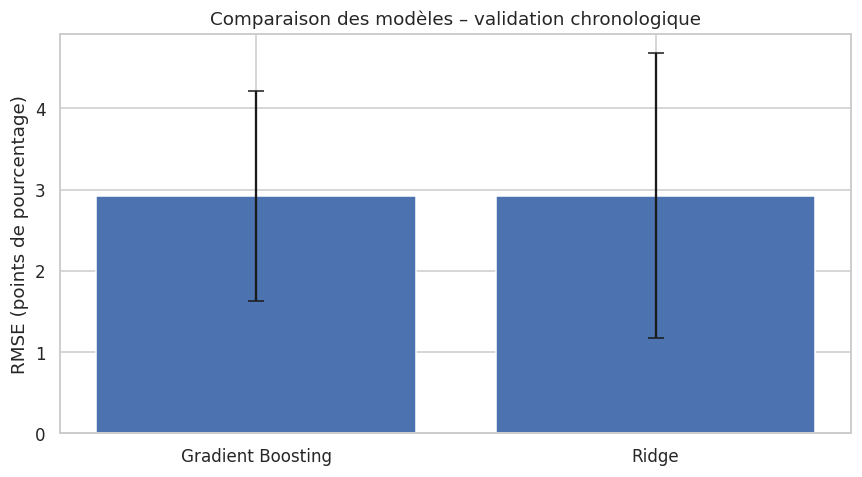

In [22]:
# Visualisation des RMSE de validation croisée
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(
    tableau_cv["Modèle"], tableau_cv["RMSE moyen CV"],
    yerr=tableau_cv["Écart-type CV"], capsize=5
)
ax.set_ylabel("RMSE (points de pourcentage)")
ax.set_title("Comparaison des modèles – validation chronologique")
plt.tight_layout()
plt.show()

**Lecture.** Le RMSE mesure l'écart quadratique moyen entre l'inflation prévue et l'inflation observée, en points de pourcentage. Plus il est faible, mieux c'est. L'écart-type des plis renseigne sur la stabilité des performances au fil des périodes.

## 7. Évaluation finale sur la période de test

La baseline prédit la valeur d'inflation connue à la date d'origine `t`. Les deux modèles sont réentraînés sur tout l'ensemble d'entraînement, puis évalués sur la période de test, qui n'a pas servi à leur apprentissage.

In [23]:
# Baseline de persistance : inflation connue au mois t
baseline_test = X_test["INFLATION_lag0"].to_numpy()

predictions = {"Dernière valeur (baseline)": baseline_test}
for nom, modele in modeles.items():
    modele.fit(X_train, y_train)
    predictions[nom] = modele.predict(X_test)

def calculer_rmse(y_reel, y_pred):
    return np.sqrt(mean_squared_error(y_reel, y_pred))

resultats_test = []
for nom, pred in predictions.items():
    resultats_test.append({
        "Modèle": nom,
        "RMSE test": calculer_rmse(y_test, pred),
        "MAE test": mean_absolute_error(y_test, pred)
    })

tableau_test = pd.DataFrame(resultats_test).sort_values("RMSE test")
display(tableau_test.round(3))

,Modèle,RMSE test,MAE test
0,Dernière valeur (baseline),2.093,1.474
1,Ridge,2.649,1.942
2,Gradient Boosting,2.766,1.911


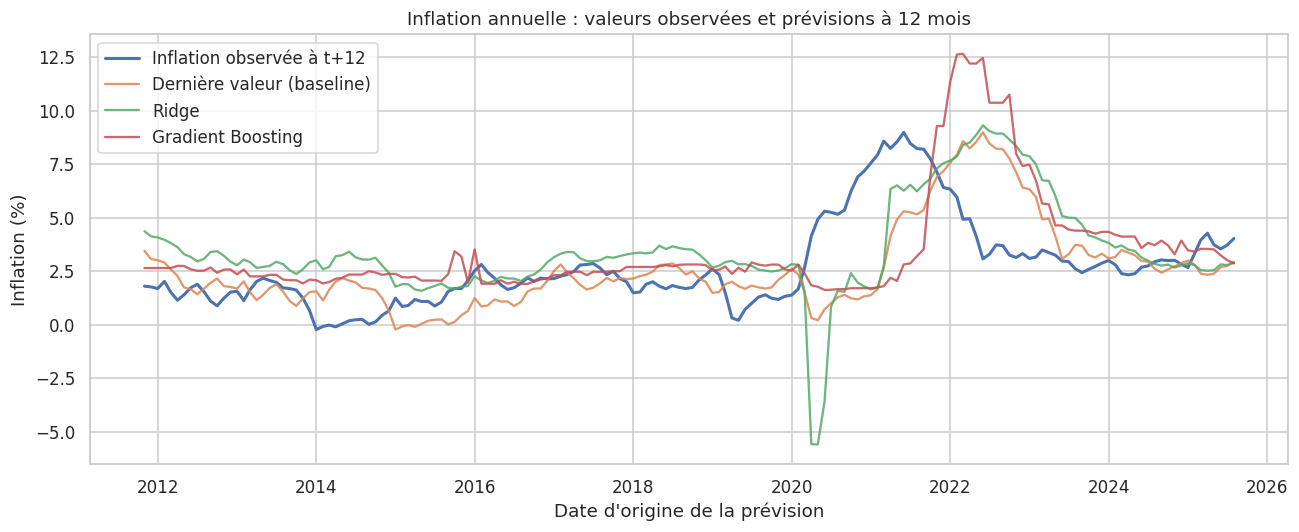

In [24]:
# Comparaison des prévisions sur la période de test
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(dates_test, y_test.to_numpy(), label="Inflation observée à t+12", linewidth=2)
for nom, pred in predictions.items():
    ax.plot(dates_test, pred, label=nom, alpha=0.85)
ax.set_title("Inflation annuelle : valeurs observées et prévisions à 12 mois")
ax.set_ylabel("Inflation (%)")
ax.set_xlabel("Date d'origine de la prévision")
ax.legend()
plt.tight_layout()
plt.show()

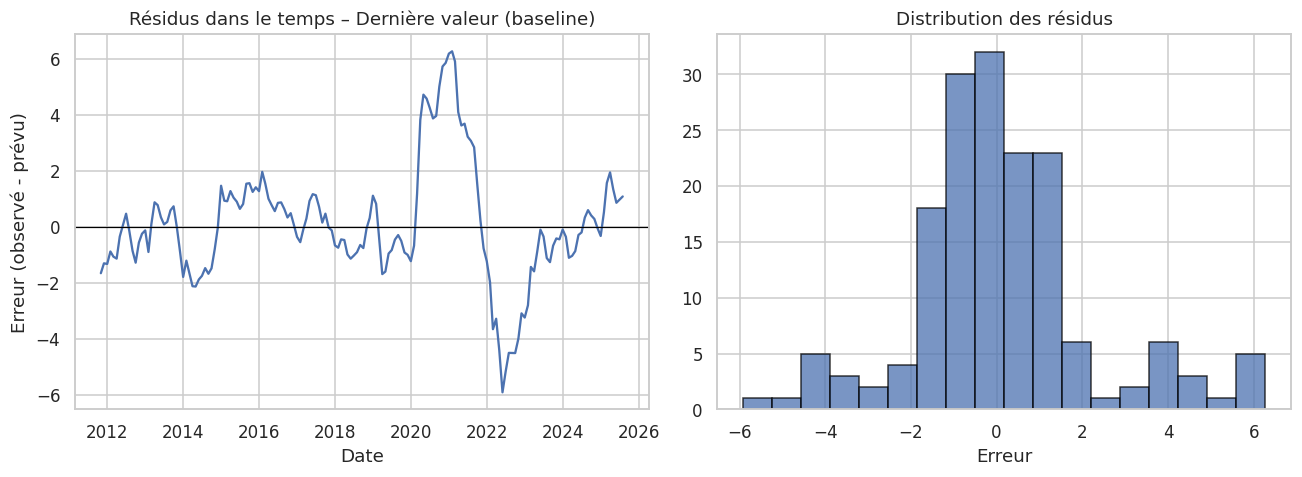

In [25]:
# Résidus du meilleur modèle selon le RMSE de test
meilleur_nom = tableau_test.iloc[0]["Modèle"]
residus = y_test.to_numpy() - predictions[meilleur_nom]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(dates_test, residus)
axes[0].axhline(0, color="black", linewidth=0.8)
axes[0].set_title(f"Résidus dans le temps – {meilleur_nom}")
axes[0].set_ylabel("Erreur (observé - prévu)")
axes[0].set_xlabel("Date")
axes[1].hist(residus, bins=18, edgecolor="black", alpha=0.75)
axes[1].set_title("Distribution des résidus")
axes[1].set_xlabel("Erreur")
plt.tight_layout()
plt.show()

**Interprétation à rédiger après exécution.** Comparer le RMSE de chaque modèle à celui de la baseline. Si Ridge ou Gradient Boosting obtient un RMSE inférieur, les indicateurs ajoutent une information prédictive à la simple persistance de l'inflation. Si aucun ne bat la baseline, cela signifie que, dans cette configuration et sur cette période de test, les variables explicatives n'améliorent pas la prévision.

## 8. Importance des variables

L'importance par permutation mesure la hausse du RMSE lorsque les valeurs d'une variable sont mélangées. Une hausse importante indique que le modèle dépend davantage de cette variable pour ses prévisions.

On calcule cette importance sur le jeu de test, avec le modèle Gradient Boosting. Elle décrit une contribution prédictive dans ce modèle, et non une relation de causalité.

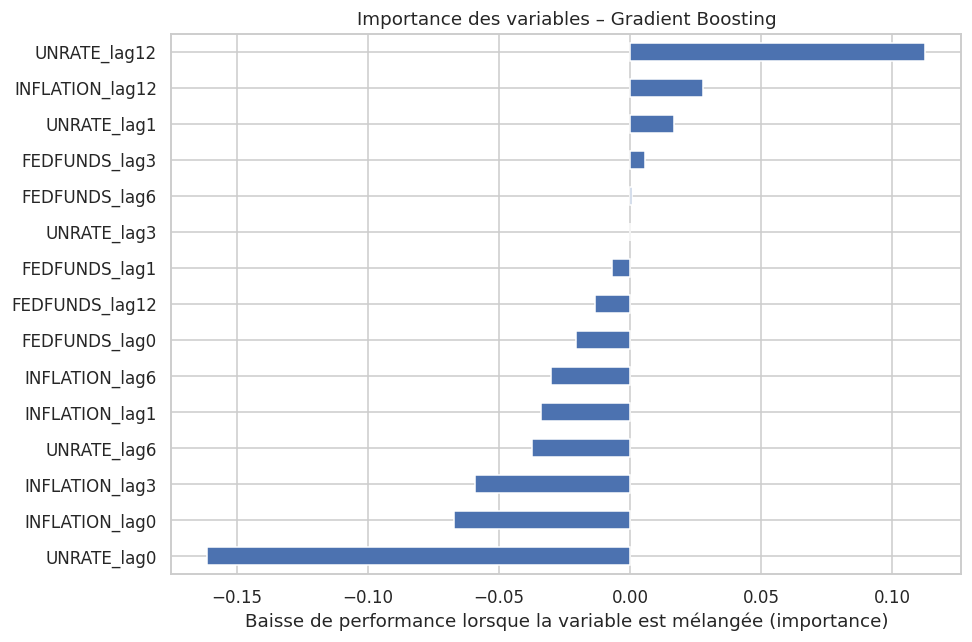

,Importance moyenne
UNRATE_lag12,0.1126
INFLATION_lag12,0.0277
UNRATE_lag1,0.0169
FEDFUNDS_lag3,0.0058
FEDFUNDS_lag6,0.0008
UNRATE_lag3,0.0000
FEDFUNDS_lag1,-0.0069
FEDFUNDS_lag12,-0.0134
FEDFUNDS_lag0,-0.0206
INFLATION_lag6,-0.0300


In [26]:
gb_entraine = modeles["Gradient Boosting"]
importance = permutation_importance(
    gb_entraine, X_test, y_test,
    scoring="neg_root_mean_squared_error",
    n_repeats=20, random_state=42
)

importance_variables = pd.Series(
    importance.importances_mean,
    index=colonnes_features
).sort_values()

fig, ax = plt.subplots(figsize=(9, 6))
importance_variables.plot.barh(ax=ax)
ax.set_xlabel("Baisse de performance lorsque la variable est mélangée (importance)")
ax.set_title("Importance des variables – Gradient Boosting")
plt.tight_layout()
plt.show()

display(importance_variables.sort_values(ascending=False).to_frame("Importance moyenne").round(4))